In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from itertools import pairwise

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

events = pd.read_csv(DATA_PATH)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

events = events.sort_values(
    ["visitorid", "timestamp"]
).reset_index(drop=True)

events["event"] = events["event"].astype("category")

print("Rows:", len(events))
print("Unique users:", events["visitorid"].nunique())
print("Date range:", events["timestamp"].min(), "—", events["timestamp"].max())

events.head()

Rows: 2756101
Unique users: 1407580
Date range: 2015-05-03 03:00:04.384000+00:00 — 2015-09-18 02:59:47.788000+00:00


,timestamp,visitorid,event,itemid,transactionid
0,2015-09-11 20:49:49.439+00:00,0,view,285930,NaN
1,2015-09-11 20:52:39.591+00:00,0,view,357564,NaN
2,2015-09-11 20:55:17.175+00:00,0,view,67045,NaN
3,2015-08-13 17:46:06.444+00:00,1,view,72028,NaN
4,2015-08-07 17:51:44.567+00:00,2,view,325215,NaN


In [2]:
SESSION_GAP = pd.Timedelta(minutes=30)

events["previous_timestamp"] = (
    events.groupby("visitorid")["timestamp"].shift(1)
)

events["time_since_previous"] = (
    events["timestamp"] - events["previous_timestamp"]
)

events["new_session"] = (
    events["previous_timestamp"].isna()
    | (events["time_since_previous"] > SESSION_GAP)
)

events["session_number"] = (
    events.groupby("visitorid")["new_session"].cumsum()
)

events["session_id"] = (
    events["visitorid"].astype(str)
    + "_"
    + events["session_number"].astype(str)
)

In [3]:
def compress_sequence(sequence):
    compressed = []

    for event in sequence:
        if not compressed or compressed[-1] != event:
            compressed.append(event)

    return compressed


session_sequences = (
    events.groupby("session_id", sort=False)["event"]
    .apply(lambda x: compress_sequence(x.tolist()))
    .reset_index(name="sequence")
)

session_sequences["sequence_length"] = (
    session_sequences["sequence"].str.len()
)

session_sequences.head()

,session_id,sequence,sequence_length
0,0_1,[view],1
1,1_1,[view],1
2,2_1,[view],1
3,3_1,[view],1
4,4_1,[view],1


In [4]:
session_sequences["path"] = (
    session_sequences["sequence"]
    .apply(lambda x: " → ".join(x))
)

top_paths = (
    session_sequences["path"]
    .value_counts()
    .head(15)
    .rename_axis("path")
    .reset_index(name="sessions")
)

top_paths["share"] = (
    top_paths["sessions"] / len(session_sequences)
)

top_paths

,path,sessions,share
0,view,1715386,0.973724
1,view → addtocart,13204,0.007495
2,view → addtocart → view,8892,0.005047
3,view → addtocart → transaction,4729,0.002684
4,addtocart,4409,0.002503
5,addtocart → view,1716,0.000974
6,view → addtocart → transaction → view,1645,0.000934
7,view → addtocart → view → addtocart → view,1092,0.000620
8,view → transaction,1078,0.000612
9,view → addtocart → view → transaction,972,0.000552


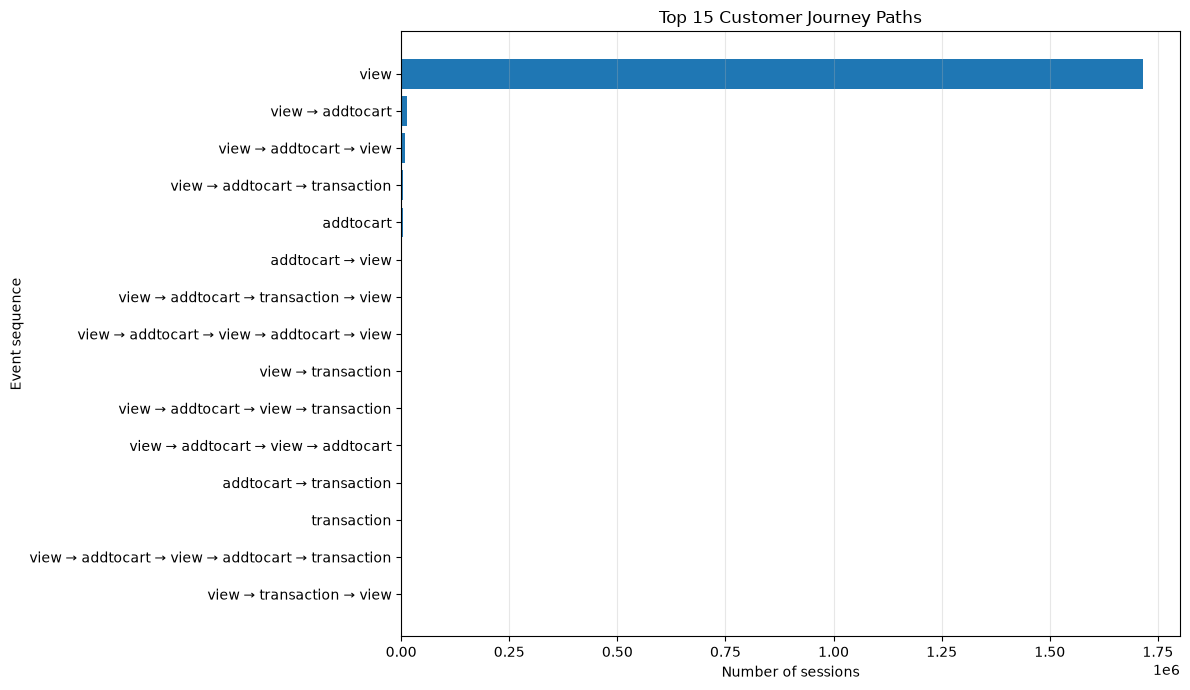

In [5]:
plot_data = top_paths.sort_values("sessions")

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    plot_data["path"],
    plot_data["sessions"]
)

ax.set_title("Top 15 Customer Journey Paths")
ax.set_xlabel("Number of sessions")
ax.set_ylabel("Event sequence")

ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_top_customer_journey_paths.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [6]:
transitions = []

for sequence in session_sequences["sequence"]:
    for source, target in pairwise(sequence):
        transitions.append((source, target))

transition_df = pd.DataFrame(
    transitions,
    columns=["source", "target"]
)

transition_counts = (
    transition_df.groupby(["source", "target"])
    .size()
    .reset_index(name="transitions")
)

transition_matrix = transition_counts.pivot(
    index="source",
    columns="target",
    values="transitions"
).fillna(0)

transition_matrix

target,addtocart,transaction,view
source,,,
addtocart,0.0,12136.0,26256.0
transaction,242.0,0.0,7382.0
view,49710.0,4544.0,0.0


In [7]:
transition_probabilities = transition_matrix.div(
    transition_matrix.sum(axis=1),
    axis=0
)

transition_probabilities

target,addtocart,transaction,view
source,,,
addtocart,0.000000,0.316108,0.683892
transaction,0.031742,0.000000,0.968258
view,0.916246,0.083754,0.000000


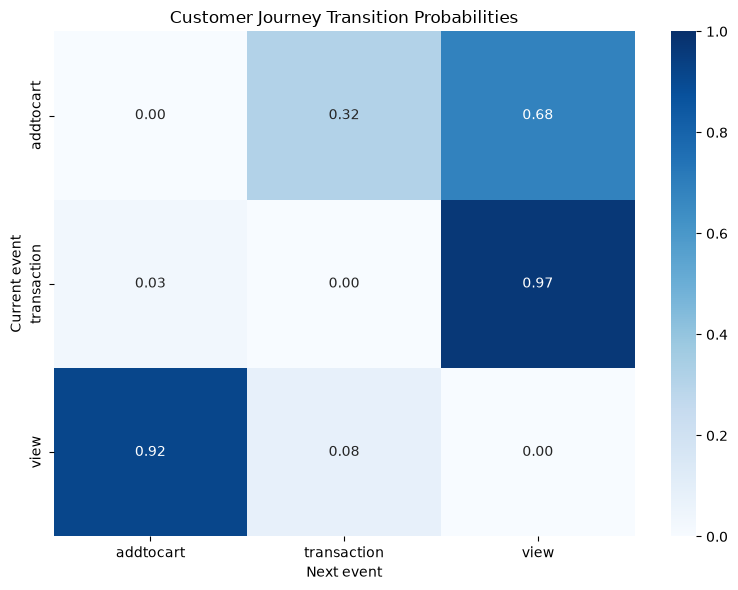

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    transition_probabilities,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    ax=ax
)

ax.set_title("Customer Journey Transition Probabilities")
ax.set_xlabel("Next event")
ax.set_ylabel("Current event")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_transition_probabilities.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [9]:
session_features = (
    events.groupby("session_id")
    .agg(
        visitorid=("visitorid", "first"),
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum()),
        events_count=("event", "size")
    )
    .reset_index()
)

session_features["has_view"] = session_features["views"] > 0
session_features["has_addtocart"] = session_features["addtocarts"] > 0
session_features["has_transaction"] = session_features["transactions"] > 0

session_stage_summary = pd.DataFrame({
    "stage": [
        "Sessions with view",
        "Sessions with addtocart",
        "Sessions with transaction"
    ],
    "sessions": [
        session_features["has_view"].sum(),
        session_features["has_addtocart"].sum(),
        session_features["has_transaction"].sum()
    ]
})

session_stage_summary["share"] = (
    session_stage_summary["sessions"] / len(session_features)
)

session_stage_summary

,stage,sessions,share
0,Sessions with view,1755781,0.996654
1,Sessions with addtocart,43924,0.024933
2,Sessions with transaction,14297,0.008116


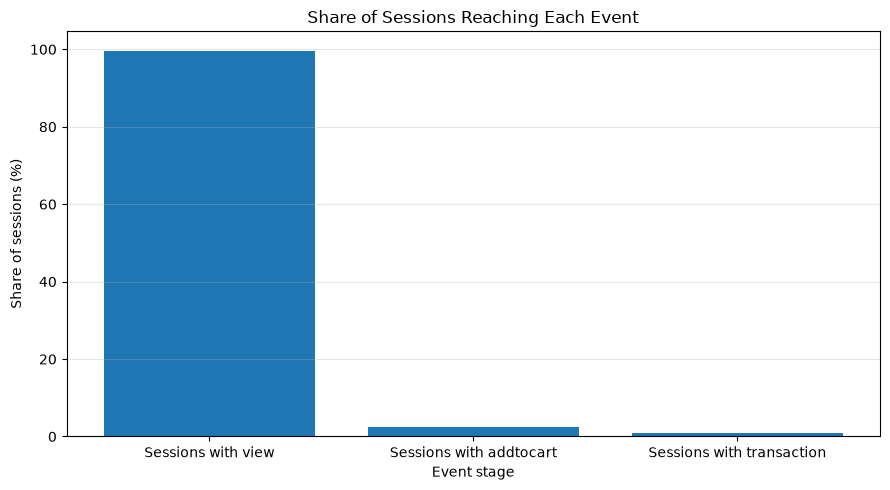

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    session_stage_summary["stage"],
    session_stage_summary["share"] * 100
)

ax.set_title("Share of Sessions Reaching Each Event")
ax.set_ylabel("Share of sessions (%)")
ax.set_xlabel("Event stage")

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_session_stage_share.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [19]:
user_features = (
    events.groupby("visitorid")
    .agg(
        total_events=("event", "size"),
        views=("event", lambda x: (x == "view").sum()),
        addtocarts=("event", lambda x: (x == "addtocart").sum()),
        transactions=("event", lambda x: (x == "transaction").sum()),
        unique_items=("itemid", "nunique"),
        first_activity=("timestamp", "min"),
        last_activity=("timestamp", "max"),
        sessions_count=("session_id", "nunique")
    )
    .reset_index()
)

active_days = (
    events.assign(
        activity_date=events["timestamp"].dt.date
    )
    .groupby("visitorid")["activity_date"]
    .nunique()
    .rename("active_days")
)

user_features = user_features.merge(
    active_days,
    on="visitorid",
    how="left"
)

observation_end = events["timestamp"].max()

user_features["days_since_last_activity"] = (
    observation_end - user_features["last_activity"]
).dt.total_seconds() / 86400

print("User features shape:", user_features.shape)

print(
    user_features[
        [
            "visitorid",
            "total_events",
            "sessions_count",
            "active_days",
            "days_since_last_activity"
        ]
    ].head()
)

print("Missing values:")
print(user_features.isna().sum())

User features shape: (1407580, 11)
   visitorid  total_events  sessions_count  active_days  \
0          0             3               1            1   
1          1             1               1            1   
2          2             8               1            1   
3          3             1               1            1   
4          4             1               1            1   

   days_since_last_activity  
0                  6.253132  
1                 35.384506  
2                 41.360300  
3                 47.825839  
4                  2.232878  
Missing values:
visitorid                   0
total_events                0
views                       0
addtocarts                  0
transactions                0
unique_items                0
first_activity              0
last_activity               0
sessions_count              0
active_days                 0
days_since_last_activity    0
dtype: int64


In [20]:
conditions = [
    user_features["transactions"] > 0,
    user_features["addtocarts"] > 0,
    user_features["views"] > 0
]

choices = [
    "Purchasers",
    "Cart Abandoners",
    "Browsers"
]

user_features["segment"] = np.select(
    conditions,
    choices,
    default="Other"
)

user_features["segment"].value_counts()

segment
Browsers           1368715
Cart Abandoners      27146
Purchasers           11719
Name: count, dtype: int64

In [21]:
segment_sizes = (
    user_features["segment"]
    .value_counts()
    .rename_axis("segment")
    .reset_index(name="users")
)

segment_sizes["share"] = (
    segment_sizes["users"] / len(user_features)
)

segment_sizes

,segment,users,share
0,Browsers,1368715,0.972389
1,Cart Abandoners,27146,0.019286
2,Purchasers,11719,0.008326


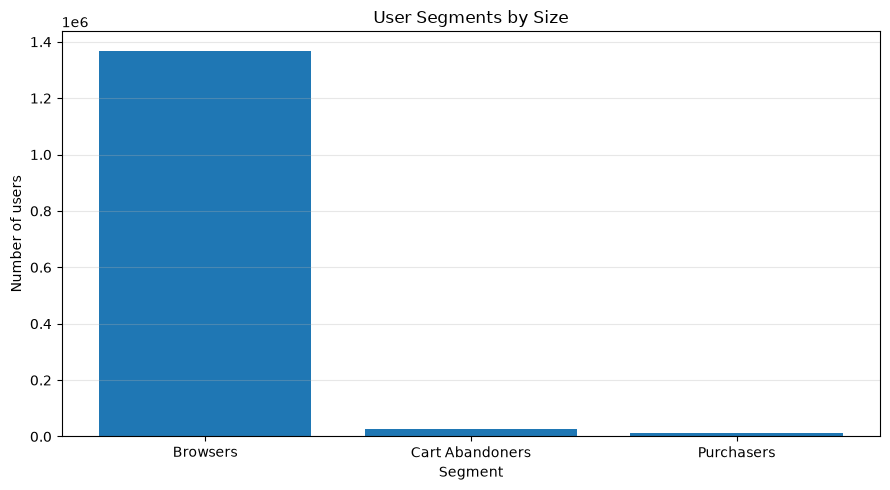

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    segment_sizes["segment"],
    segment_sizes["users"]
)

ax.set_title("User Segments by Size")
ax.set_xlabel("Segment")
ax.set_ylabel("Number of users")

ax.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_user_segment_sizes.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [23]:
segment_summary = (
    user_features.groupby("segment")
    .agg(
        users=("visitorid", "nunique"),
        avg_events=("total_events", "mean"),
        median_events=("total_events", "median"),
        avg_views=("views", "mean"),
        avg_addtocarts=("addtocarts", "mean"),
        avg_transactions=("transactions", "mean"),
        avg_unique_items=("unique_items", "mean"),
        avg_sessions=("sessions_count", "mean"),
        median_active_days=("active_days", "median")
    )
    .reset_index()
)

segment_summary

,segment,users,avg_events,median_events,avg_views,avg_addtocarts,avg_transactions,avg_unique_items,avg_sessions,median_active_days
0,Browsers,1368715,1.705565,1.0,1.705565,0.000000,0.00000,1.412073,1.215634,1.0
1,Cart Abandoners,27146,7.035696,4.0,5.493480,1.542216,0.00000,3.708650,2.029397,1.0
2,Purchasers,11719,19.684103,6.0,15.424012,2.343801,1.91629,9.538271,3.646130,1.0


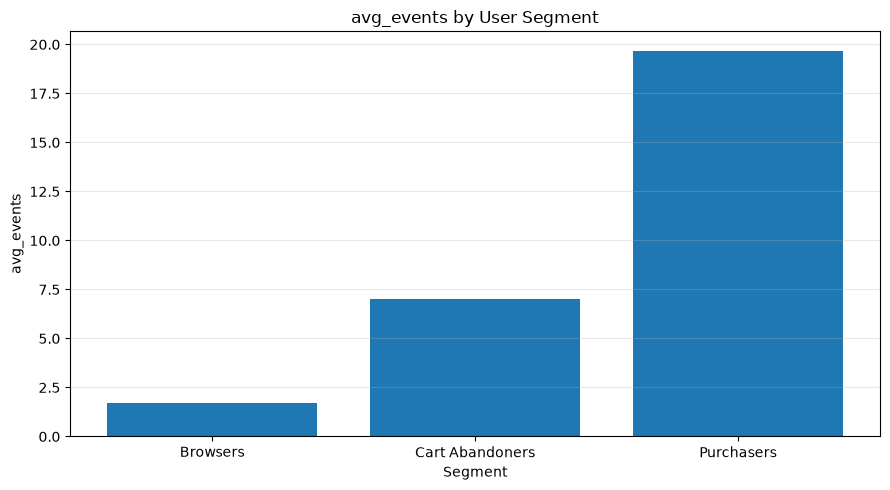

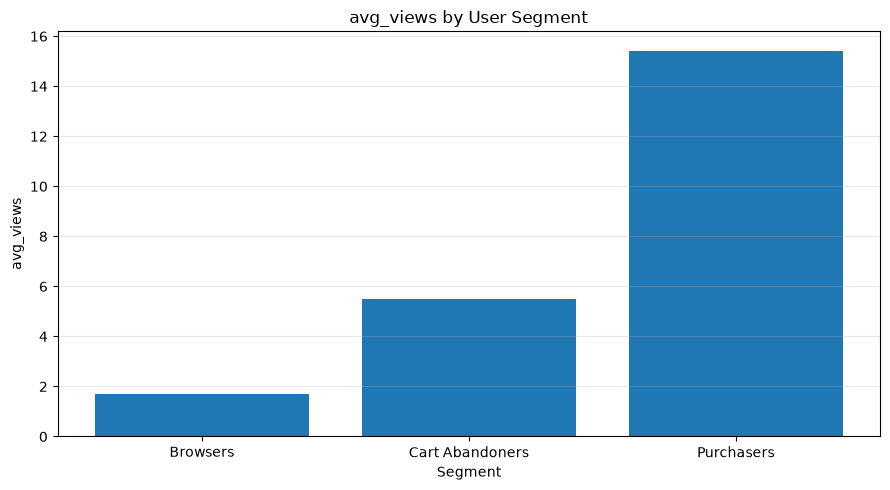

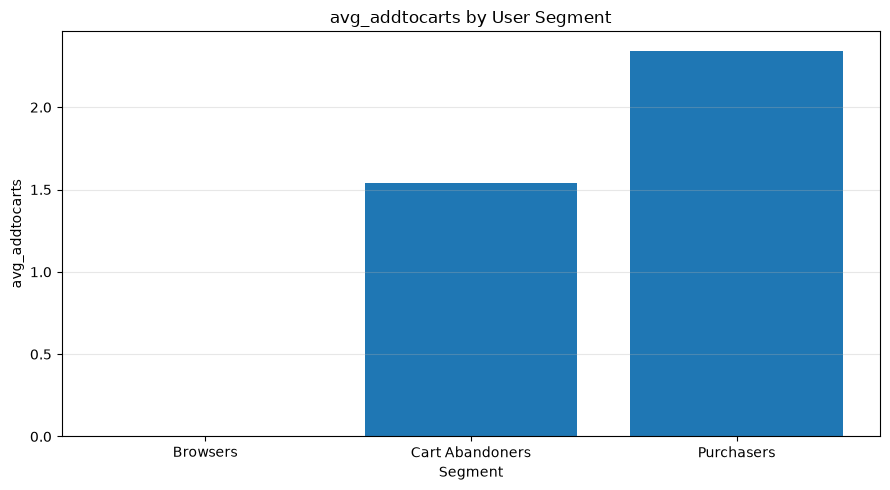

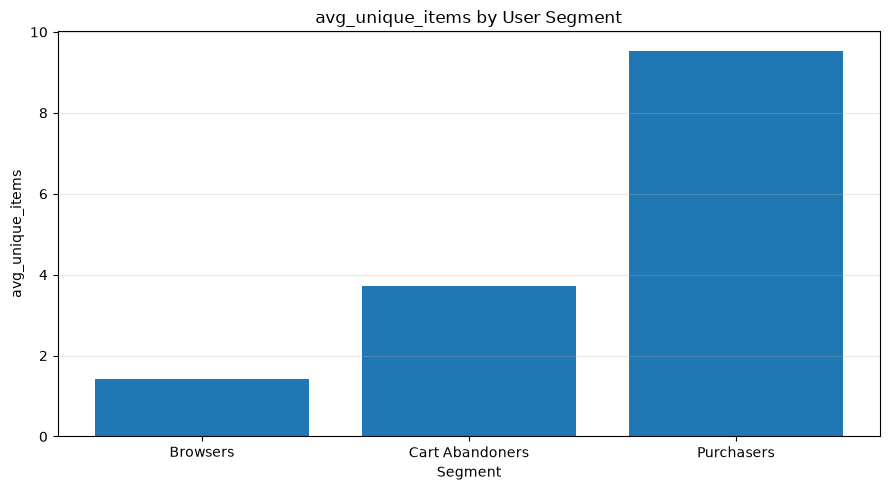

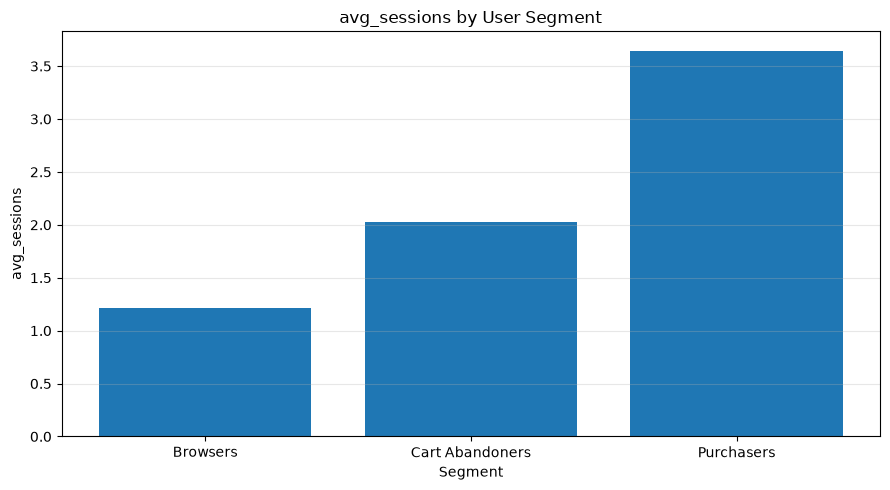

In [24]:
metrics_to_plot = [
    "avg_events",
    "avg_views",
    "avg_addtocarts",
    "avg_unique_items",
    "avg_sessions"
]

for metric in metrics_to_plot:
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(
        segment_summary["segment"],
        segment_summary[metric]
    )

    ax.set_title(f"{metric} by User Segment")
    ax.set_xlabel("Segment")
    ax.set_ylabel(metric)

    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / f"06_{metric}_by_segment.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

In [25]:
recency_summary = (
    user_features.groupby("segment")
    ["days_since_last_activity"]
    .agg(
        users="count",
        median_days="median",
        mean_days="mean",
        p90_days=lambda x: x.quantile(0.90)
    )
    .reset_index()
)

recency_summary

,segment,users,median_days,mean_days,p90_days
0,Browsers,1368715,67.140588,68.395468,123.025661
1,Cart Abandoners,27146,64.481458,66.107320,122.117979
2,Purchasers,11719,63.263466,64.763236,121.424400


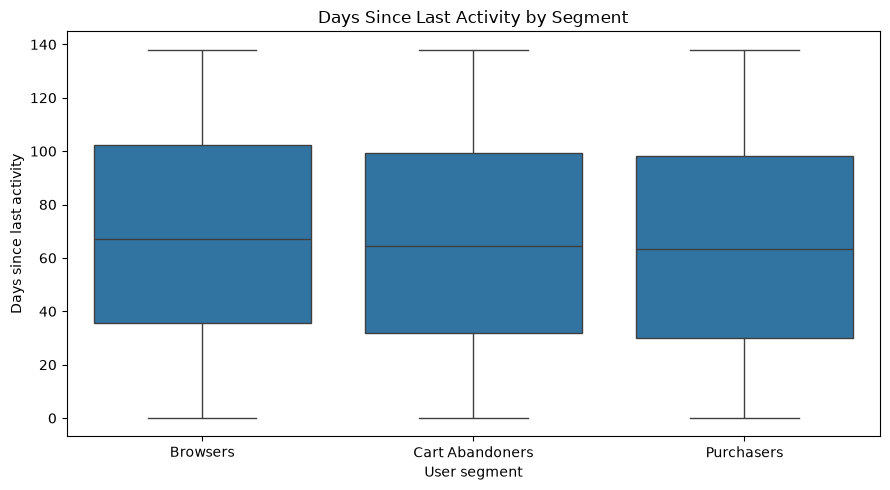

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=user_features,
    x="segment",
    y="days_since_last_activity",
    showfliers=False,
    ax=ax
)

ax.set_title("Days Since Last Activity by Segment")
ax.set_xlabel("User segment")
ax.set_ylabel("Days since last activity")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "06_segment_recency.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [27]:
print("Total users:", len(user_features))

print(
    "Users in segments:",
    user_features["segment"].value_counts().sum()
)

print(
    "Missing segments:",
    user_features["segment"].isna().sum()
)

print(
    "Unique users in segments:",
    user_features.loc[
        user_features["segment"] != "Other",
        "visitorid"
    ].nunique()
)

Total users: 1407580
Users in segments: 1407580
Missing segments: 0
Unique users in segments: 1407580


In [28]:
top_paths.to_csv(
    TABLES_DIR / "06_top_customer_journey_paths.csv",
    index=False
)

transition_matrix.to_csv(
    TABLES_DIR / "06_transition_matrix.csv"
)

transition_probabilities.to_csv(
    TABLES_DIR / "06_transition_probabilities.csv"
)

session_stage_summary.to_csv(
    TABLES_DIR / "06_session_stage_summary.csv",
    index=False
)

user_features.to_csv(
    TABLES_DIR / "06_user_features_segments.csv",
    index=False
)

segment_sizes.to_csv(
    TABLES_DIR / "06_segment_sizes.csv",
    index=False
)

segment_summary.to_csv(
    TABLES_DIR / "06_segment_summary.csv",
    index=False
)

recency_summary.to_csv(
    TABLES_DIR / "06_segment_recency.csv",
    index=False
)

print("Notebook 06 results saved successfully.")

Notebook 06 results saved successfully.


In [29]:
transaction_users = set(
    events.loc[
        events["event"] == "transaction",
        "visitorid"
    ].unique()
)

print("Users with transaction:", len(transaction_users))

cart_users = set(
    events.loc[
        events["event"] == "addtocart",
        "visitorid"
    ].unique()
)

print(
    "Transaction users without addtocart:",
    len(transaction_users - cart_users)
)

view_users = set(
    events.loc[
        events["event"] == "view",
        "visitorid"
    ].unique()
)

print(
    "Transaction users without view:",
    len(transaction_users - view_users)
)

Users with transaction: 11719
Transaction users without addtocart: 1143
Transaction users without view: 428


In [30]:
transaction_diagnostics = pd.DataFrame({
    "metric": [
        "Users with transaction",
        "Transaction without addtocart",
        "Transaction without view"
    ],
    "users": [
        len(transaction_users),
        len(transaction_users - cart_users),
        len(transaction_users - view_users)
    ]
})

transaction_diagnostics["share_of_transaction_users"] = (
    transaction_diagnostics["users"] / len(transaction_users)
)

transaction_diagnostics.to_csv(
    TABLES_DIR / "06_transaction_diagnostics.csv",
    index=False
)

transaction_diagnostics

,metric,users,share_of_transaction_users
0,Users with transaction,11719,1.000000
1,Transaction without addtocart,1143,0.097534
2,Transaction without view,428,0.036522
